# Flash drought decomposition projections results

In [1]:
import glob as glob
import xarray as xr
import pandas as pd
import geopandas as gpd
import sys
import os
import numpy as np
import time
import zarr
import matplotlib.pyplot as plt

In [2]:
sys.path.append('/g/data/mn51/users/jb6465/code/flash-drought/attribution-python')
from attribution import *
from plotting import *
from extract import *

In [4]:
import warnings
import logging
warnings.filterwarnings('ignore') 
logging.getLogger("distributed.worker.memory").setLevel(logging.ERROR)
logging.getLogger("distributed.shuffle._scheduler_plugin").setLevel(logging.ERROR)
logging.getLogger('flox').setLevel(logging.WARNING)
np_divide_error = np.seterr(invalid='ignore')

In [5]:
import dask
import tempfile
from dask.diagnostics import ProgressBar
from dask.distributed import Client, LocalCluster

dask.config.set({
    'array.chunk-size': "256 MiB",
    'array.slicing.split_large_chunks': True, #This can make AXIOM very slow
    'distributed.comm.timeouts.connect': '120s',
    'distributed.comm.timeouts.tcp': '120s',
    'distributed.comm.retry.count': 20,
    'distributed.scheduler.allowed-failures': 40,
    "distributed.scheduler.worker-saturation": 1.1, #This should use the new behaviour which helps with memory pile up
})

# client = dask.distributed.Client()
client = Client(n_workers=10, threads_per_worker=1, local_directory = tempfile.mkdtemp(), memory_limit = "1000000mb") #"252000mb") #larger memory required to compute ET0/sensitvities, smaller for plotting/analysis
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 10
Total threads: 10,Total memory: 9.09 TiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:45421,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:40469,Total threads: 1
Dashboard: /proxy/38701/status,Memory: 0.91 TiB
Nanny: tcp://127.0.0.1:37803,


## Compute $ET_0$ (projections)

In [6]:
sys.path.append('/g/data/mn51/users/jb6465/code/hazard-drought-exp/submodules/dataset_finder')
from dataset_finder import *

In [7]:
%%time
ACS_downscaled_historical = get_datasets("NHP", scenario = "historical" , timescale='day', var=['sfcWindAdjust', 'tasAdjust', 'tasmaxAdjust', 'tasminAdjust', 'rsdsAdjust', 'hussAdjust', 'psAdjust'], grid=("AUST-05i"))
ACS_downscaled_ssp370 = get_datasets("NHP", scenario = "ssp370" , timescale='day', var=['sfcWindAdjust', 'tasAdjust', 'tasmaxAdjust', 'tasminAdjust', 'rsdsAdjust', 'hussAdjust', 'psAdjust'], grid=("AUST-05i"))
ACS_downscaled_ssp126 = get_datasets("NHP", scenario = "ssp126" , timescale='day', var=['sfcWindAdjust', 'tasAdjust', 'tasmaxAdjust', 'tasminAdjust', 'rsdsAdjust', 'hussAdjust', 'psAdjust'], grid=("AUST-05i"))

CPU times: user 3.08 s, sys: 977 ms, total: 4.05 s
Wall time: 4.99 s


In [8]:
ACS_downscaled_historical

,grid,org,gcm,scenario,mdl_run,rcm,ver,bc_org,bc,ref,bc_period,timescale,,var,date_created,year
0,AUST-05i,BOM,ACCESS-CM2,historical,r4i1p1f1,BARPA-R,v1-r1,NHP,MRNBC,BARRAR2,1980-2022,day,,"hussAdjust, psAdjust, rsdsAdjust, sfcWindAdjust, tasAdjust, tasmaxAdjust, tasminAdjust",v20250311,1960 to 2014
1,AUST-05i,BOM,ACCESS-ESM1-5,historical,r6i1p1f1,BARPA-R,v1-r1,NHP,MRNBC,BARRAR2,1980-2022,day,,"hussAdjust, psAdjust, rsdsAdjust, sfcWindAdjust, tasAdjust, tasmaxAdjust, tasminAdjust",v20250311,1960 to 2014
2,AUST-05i,BOM,CESM2,historical,r11i1p1f1,BARPA-R,v1-r1,NHP,MRNBC,BARRAR2,1980-2022,day,,"hussAdjust, psAdjust, rsdsAdjust, sfcWindAdjust, tasAdjust, tasmaxAdjust, tasminAdjust",v20250311,1960 to 2014
3,AUST-05i,BOM,CMCC-ESM2,historical,r1i1p1f1,BARPA-R,v1-r1,NHP,MRNBC,BARRAR2,1980-2022,day,,"hussAdjust, psAdjust, rsdsAdjust, sfcWindAdjust, tasAdjust, tasmaxAdjust, tasminAdjust",v20250311,1960 to 2014
4,AUST-05i,BOM,EC-Earth3,historical,r1i1p1f1,BARPA-R,v1-r1,NHP,MRNBC,BARRAR2,1980-2022,day,,"hussAdjust, psAdjust, rsdsAdjust, sfcWindAdjust, tasAdjust, tasmaxAdjust, tasminAdjust",v20250311,1960 to 2014
5,AUST-05i,BOM,MPI-ESM1-2-HR,historical,r1i1p1f1,BARPA-R,v1-r1,NHP,MRNBC,BARRAR2,1980-2022,day,,"hussAdjust, psAdjust, rsdsAdjust, sfcWindAdjust, tasAdjust, tasmaxAdjust, tasminAdjust",v20250311,1960 to 2014
6,AUST-05i,BOM,NorESM2-MM,historical,r1i1p1f1,BARPA-R,v1-r1,NHP,MRNBC,BARRAR2,1980-2022,day,,"hussAdjust, psAdjust, rsdsAdjust, sfcWindAdjust, tasAdjust, tasmaxAdjust, tasminAdjust",v20250311,1960 to 2014
7,AUST-05i,CSIRO,ACCESS-CM2,historical,r4i1p1f1,CCAM-v2203-SN,v1-r1,NHP,MRNBC,BARRAR2,1980-2022,day,,"hussAdjust, psAdjust, rsdsAdjust, sfcWindAdjust, tasAdjust, tasmaxAdjust, tasminAdjust",v20250311,1960 to 2014
8,AUST-05i,CSIRO,ACCESS-ESM1-5,historical,r6i1p1f1,CCAM-v2203-SN,v1-r1,NHP,MRNBC,BARRAR2,1980-2022,day,,"hussAdjust, psAdjust, rsdsAdjust, sfcWindAdjust, tasAdjust, tasmaxAdjust, tasminAdjust",v20250311,1960 to 2014
9,AUST-05i,CSIRO,CESM2,historical,r11i1p1f1,CCAM-v2203-SN,v1-r1,NHP,MRNBC,BARRAR2,1980-2022,day,,"hussAdjust, psAdjust, rsdsAdjust, sfcWindAdjust, tasAdjust, tasmaxAdjust, tasminAdjust",v20250311,1960 to 2014


In [ ]:
%%time
#compute ET0 and sensitivities ~ fastest and least memory intensive to create annual zarr files using dask
scenario_files = {'historical':ACS_downscaled_historical, 'ssp370':ACS_downscaled_ssp370, 'ssp126':ACS_downscaled_ssp126}
scen_input = 'historical'
save_dir = '/g/data/mn51/users/jb6465/data/flash_drought/projections'
for ens_idx in range(0,14):
    #get info for save string
    GCM = str(scenario_files[scen_input][ens_idx]).split('\n')[3].split()[-1]
    variant = str(scenario_files[scen_input][ens_idx]).split('\n')[5].split()[-1]
    RCM = str(scenario_files[scen_input][ens_idx]).split('\n')[6].split()[-1]
    BC = str(scenario_files[scen_input][ens_idx]).split('\n')[8].split()[-1]+'_'+str(scenario_files[scen_input][ens_idx]).split('\n')[9].split()[-1]+'_'+str(scenario_files[scen_input][ens_idx]).split('\n')[10].split()[-1]
    scenario_years = {'historical':range(1960, 2015), 'ssp370':range(2015, 2101 if RCM == 'BARPA-R' else 2100), 'ssp126':range(2015,  2101 if RCM == 'BARPA-R' else 2100)}
        
    if not os.path.exists(f"{save_dir}/{GCM}_{variant}_{RCM}/{scen_input}/{scenario_years[scen_input][-1]}-{GCM}_{variant}_{RCM}_{BC}_ET0_tall_and_driver_sensitivities.zarr"):
        print(scenario_files[scen_input][ens_idx])
        
        #ingest inputs 
        Rs = xr.open_mfdataset(scenario_files[scen_input][ens_idx].select(var='rsdsAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').rsdsAdjust
        T = xr.open_mfdataset(scenario_files[scen_input][ens_idx].select(var='tasAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').tasAdjust
        Tmax = xr.open_mfdataset(scenario_files[scen_input][ens_idx].select(var='tasmaxAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').tasmaxAdjust
        Tmin = xr.open_mfdataset(scenario_files[scen_input][ens_idx].select(var='tasminAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').tasminAdjust
        Patm = xr.open_mfdataset(scenario_files[scen_input][ens_idx].select(var='psAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').psAdjust
        Q2M = xr.open_mfdataset(scenario_files[scen_input][ens_idx].select(var='hussAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').hussAdjust
        W10M = xr.open_mfdataset(scenario_files[scen_input][ens_idx].select(var='sfcWindAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').sfcWindAdjust 
        elev = xr.open_dataset(glob.glob(f'/g/data/ia39/australian-climate-service/release/CORDEX/output-CMIP6/DD/AUST-05i/BOM/{GCM}/historical/{variant}/{RCM}/v1-r1/fx/orog/v20250311/*.nc')[0] if RCM == 'BARPA-R' else glob.glob(f'/g/data/ia39/australian-climate-service/release/CORDEX/output-CMIP6/DD/AUST-05i/CSIRO/{GCM}/historical/{variant}/{RCM}/v1-r1/fx/orog/v20250311/*.nc')[0]).orog

        # compute ET0 annually
        for year in scenario_years[scen_input]:
            if not os.path.exists(f"{save_dir}/{GCM}_{variant}_{RCM}/{scen_input}/{year}-{GCM}_{variant}_{RCM}_{BC}_ET0_tall_and_driver_sensitivities.zarr"):
                start = time.time()
                #compute ET0 and components
                ET0 = compute_and_decompose_ET0((Rs.chunk({'time':365, 'lat':'auto', 'lon':'auto'}).sel(time=str(year)))*86400,
                                                T.chunk({'time':365, 'lat':'auto', 'lon':'auto'}).sel(time=str(year)),
                                                Tmax.chunk({'time':365, 'lat':'auto', 'lon':'auto'}).sel(time=str(year)),
                                                Tmin.chunk({'time':365, 'lat':'auto', 'lon':'auto'}).sel(time=str(year)),
                                                None, #Tdew
                                                Patm.chunk({'time':365, 'lat':'auto', 'lon':'auto'}).sel(time=str(year)),
                                                W10M.chunk({'time':365, 'lat':'auto', 'lon':'auto'}).sel(time=str(year)),
                                                Q2M.chunk({'time':365, 'lat':'auto', 'lon':'auto'}).sel(time=str(year)), 
                                                None, None, None, #RH vars
                                                elev,
                                                derive_2m_windspeed=True, short_tall_crop_switch='tall', T2M_model_or_derived='derived', Patm_model_or_derived='model', esat_method='TmaxTmin', eact_method='Patm_q', Rnl_method='TmaxTmin')
                
                #save locally as a zarr file
                os.makedirs(f"{save_dir}/{GCM}_{variant}_{RCM}/{scen_input}/", exist_ok=True)
                xr.Dataset({"ET0_tall_crop": ET0}).reset_coords(drop=True).astype('float16').to_zarr(f"/g/data/mn51/users/jb6465/data/flash_drought/projections/{GCM}_{variant}_{RCM}/{scen_input}/{year}-{GCM}_{variant}_{RCM}_{BC}_ET0_tall.zarr", consolidated=True, encoding={"ET0_tall_crop": {"compressor": zarr.Blosc(cname='zstd', clevel=5, shuffle=1)}})
                
                end = time.time()
                print(f" ~ {year} computed in {end - start:.2f} s")
    else:
        print(f'--> {GCM}_{variant}_{RCM} for {scen_input} already computed in {save_dir}/{GCM}_{variant}_{RCM}/')

## $ET_0$ means and variabilities

In [ ]:
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [ ]:
mean_dict = {}
var_dict = {}

In [ ]:
%%time
for ens_member in os.listdir('/g/data/mn51/users/jb6465/data/flash_drought/projections/'):
    print(f'~ {ens_member}')
    ET0 = xr.open_mfdataset(glob.glob(f'/g/data/mn51/users/jb6465/data/flash_drought/projections/{ens_member}/historical/*.zarr'), concat_dim='time', combine='nested', chunks={'time': -1, 'lat': 'auto', 'lon': 'auto'}).ET0_tall_crop.sortby('time')
    ET0 = ET0.sel(time=ET0['time'].dt.year.isin(range(1980, 2015))) #need to use this format to avoid ccam cftime errors
    mean_dict[ens_member] = ((ET0.assign_coords(doy=ET0['time'].dt.dayofyear).groupby('doy').mean('time')).mean(dim='doy')).compute()
    var_dict[ens_member] = ((ET0.assign_coords(doy=ET0['time'].dt.dayofyear).groupby('doy').mean('time')).var(dim='doy')).compute()
    # break

In [11]:
mean_dict = dict(sorted(mean_dict.items()))
var_dict = dict(sorted(var_dict.items()))

In [16]:
BARRA_ET0 = xr.open_mfdataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/ET0/*.nc').chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).ET0_tall_crop.sortby('time').sel(time=slice('1980', '2014'))
BARRA_ET0_mean = ((BARRA_ET0.assign_coords(doy=BARRA_ET0['time'].dt.dayofyear).groupby('doy').mean('time')).mean(dim='doy')).compute()
BARRA_ET0_var = ((BARRA_ET0.assign_coords(doy=BARRA_ET0['time'].dt.dayofyear).groupby('doy').mean('time')).var(dim='doy')).compute()

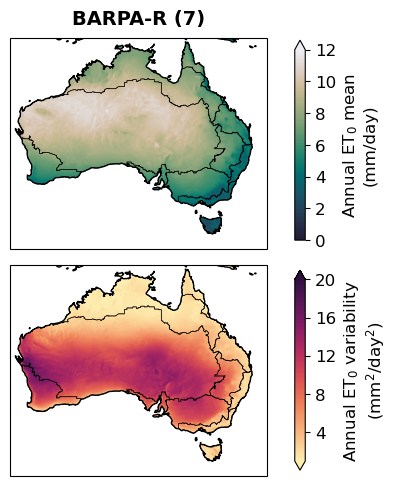

In [17]:
import cmocean

create_multiplot(nrows=2, ncols=1, plot_fontsize=12, title_size=14, figsize=(3.5, 5), plot_extent=[112, 156.2, -44, -10],
    plot_list=[[mask_ocean(xr.concat([v for k, v in mean_dict.items() if "BARPA-R" in k], dim="MME").median(dim='MME'))],
               [mask_ocean(xr.concat([v for k, v in var_dict.items() if "BARPA-R" in k], dim="MME").median(dim='MME'))]],
    shapefile = 'NRM',
    shapefile_linewidth = 0.4,
    col_titles=['BARPA-R (7)'],
    col_titles_all_rows_switch=False,
    cmap_list=[cmocean.cm.rain_r, cmocean.cm.matter],
    cbar_labels=['Annual ET$_0$ mean\n(mm/day)', 'Annual ET$_0$ variability\n(mm$^2$/day$^2$)'],
    cbar_extensions=['max','both'],
    cbar_width=0.03,
    cbar_height = 0.4,
    cbar_nticks=[7, 5],
    cbar_tick_labels = None,
    cbar_x_y_loc = (0.92, 0.045),
    cbar_mins=[0,1],
    cbar_maxs=[12,20])


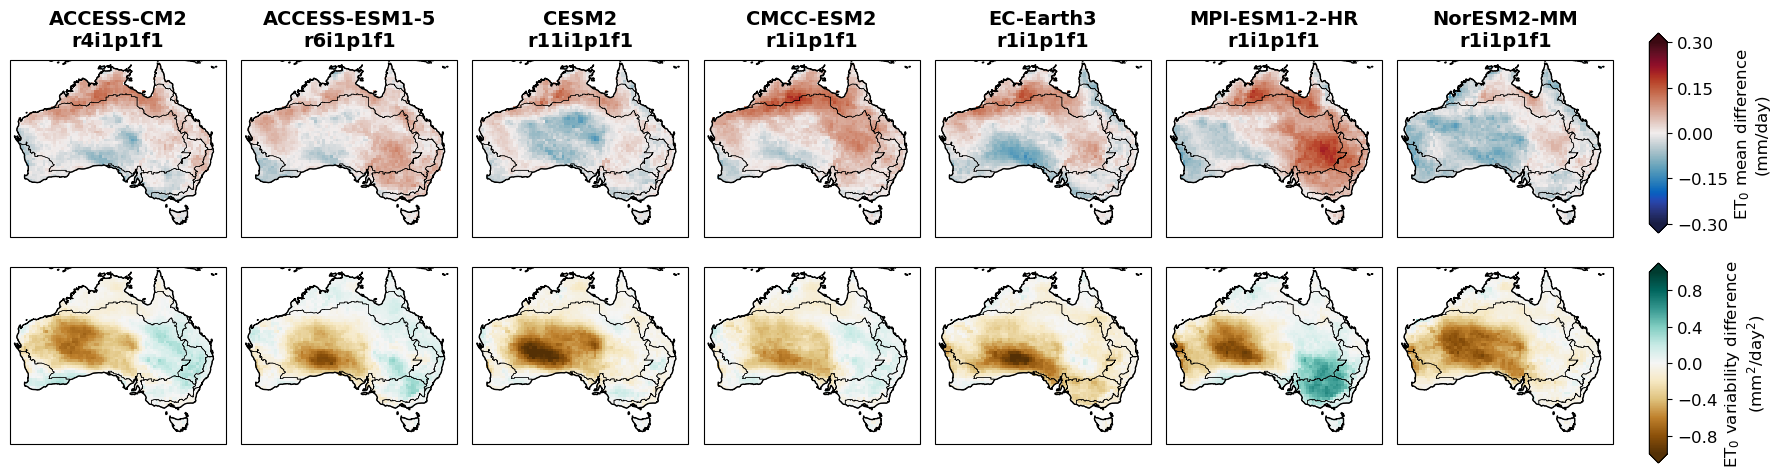

In [18]:
import cmocean

create_multiplot(nrows=2, ncols=7, plot_fontsize=12, title_size=14, figsize=(18, 5), plot_extent=[112, 156.2, -44, -10],
    plot_list=[[(mean_dict[k] - BARRA_ET0_mean) for k in mean_dict.keys() if "BARPA-R" in k],
               [(var_dict[k] - BARRA_ET0_var) for k in var_dict.keys() if "BARPA-R" in k]],
    shapefile = 'NRM',
    shapefile_linewidth = 0.4,
    col_titles=[title.replace('_'+title.split('_')[-1],'').replace('_','\n') for title in list(mean_dict.keys()) if "BARPA-R" in title],
    col_titles_all_rows_switch=False,
    cmap_list=[cmocean.cm.balance, plt.cm.BrBG],
    cbar_labels=['ET$_0$ mean difference\n(mm/day)', 'ET$_0$ variability difference\n(mm$^2$/day$^2$)'],
    cbar_extensions=['both','both'],
    cbar_width=0.01,
    cbar_height = 0.4,
    cbar_nticks=[5,5],
    cbar_tick_labels = None,
    cbar_x_y_loc = (0.92, 0.045),
    cbar_mins=[-0.3,-1],
    cbar_maxs=[0.3,1])


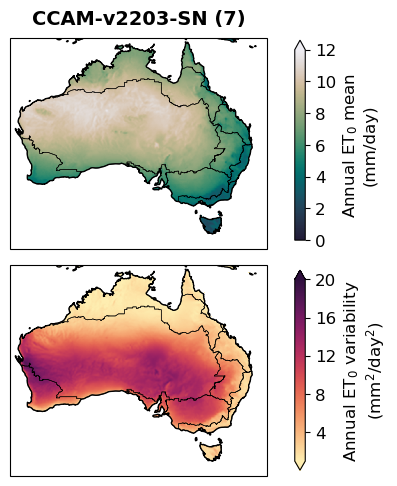

In [19]:
import cmocean

create_multiplot(nrows=2, ncols=1, plot_fontsize=12, title_size=14, figsize=(3.5, 5), plot_extent=[112, 156.2, -44, -10],
    plot_list=[[mask_ocean(xr.concat([v for k, v in mean_dict.items() if "CCAM" in k], dim="MME").median(dim='MME'))],
               [mask_ocean(xr.concat([v for k, v in var_dict.items() if "CCAM" in k], dim="MME").median(dim='MME'))]],
    shapefile = 'NRM',
    shapefile_linewidth = 0.4,
    col_titles=['CCAM-v2203-SN (7)'],
    col_titles_all_rows_switch=False,
    cmap_list=[cmocean.cm.rain_r, cmocean.cm.matter],
    cbar_labels=['Annual ET$_0$ mean\n(mm/day)', 'Annual ET$_0$ variability\n(mm$^2$/day$^2$)'],
    cbar_extensions=['max','both'],
    cbar_width=0.03,
    cbar_height = 0.4,
    cbar_nticks=[7,5],
    cbar_tick_labels = None,
    cbar_x_y_loc = (0.92, 0.045),
    cbar_mins=[0,1],
    cbar_maxs=[12,20])


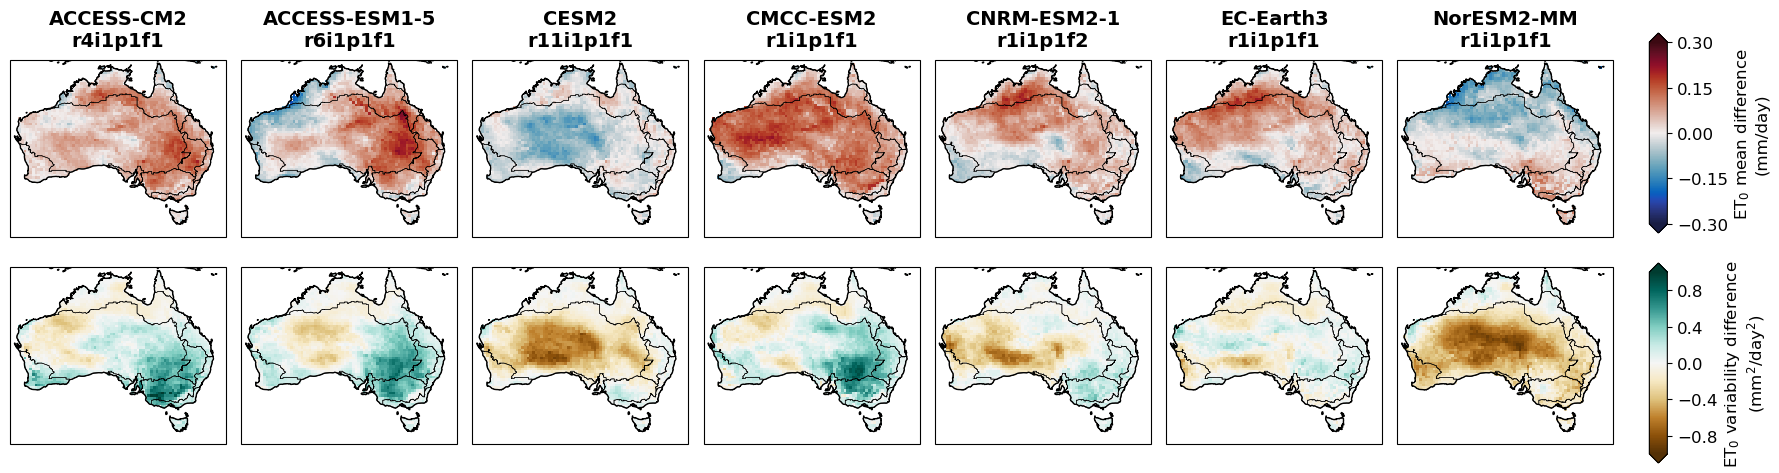

In [20]:
import cmocean

create_multiplot(nrows=2, ncols=7, plot_fontsize=12, title_size=14, figsize=(18, 5), plot_extent=[112, 156.2, -44, -10],
    plot_list=[[(mean_dict[k] - BARRA_ET0_mean) for k in mean_dict.keys() if "CCAM" in k],
               [(var_dict[k] - BARRA_ET0_var) for k in var_dict.keys() if "CCAM" in k]],
    shapefile = 'NRM',
    shapefile_linewidth = 0.4,
    col_titles=[title.replace('_'+title.split('_')[-1],'').replace('_','\n') for title in list(mean_dict.keys()) if "CCAM" in title],
    col_titles_all_rows_switch=False,
    cmap_list=[cmocean.cm.balance, plt.cm.BrBG],
    cbar_labels=['ET$_0$ mean difference\n(mm/day)', 'ET$_0$ variability difference\n(mm$^2$/day$^2$)'],
    cbar_extensions=['both','both'],
    cbar_width=0.01,
    cbar_height = 0.4,
    cbar_nticks=[5,5],
    cbar_tick_labels = None,
    cbar_x_y_loc = (0.92, 0.045),
    cbar_mins=[-0.3,-1],
    cbar_maxs=[0.3,1])


## Black summer ACCESS-ESM1-5 

In [21]:
ens_member = 'ACCESS-ESM1-5_r6i1p1f1_CCAM-v2203-SN'
ET0 = xr.open_mfdataset(glob.glob(f'/g/data/mn51/users/jb6465/data/flash_drought/projections/{ens_member}/ssp370/*.zarr'), concat_dim='time', combine='nested', chunks={'time': -1, 'lat': 'auto', 'lon': 'auto'}).ET0_tall_crop.sortby('time')

In [22]:
ET0_anom = compute_daily_anom(compute_rolling_xday(ET0, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).compute()

In [23]:
ET0_anom = mask_ocean(ET0_anom)

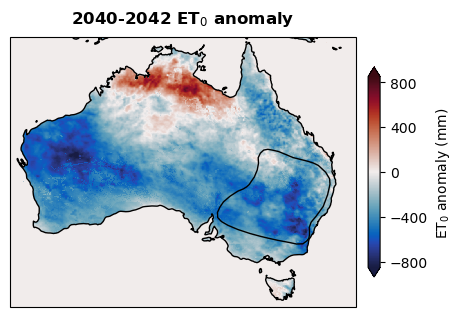

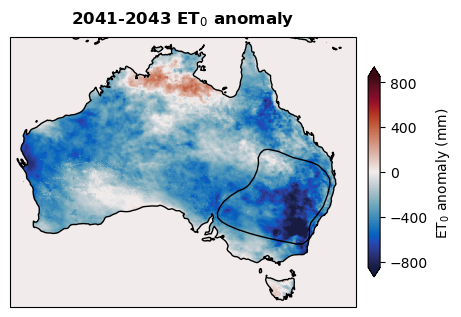

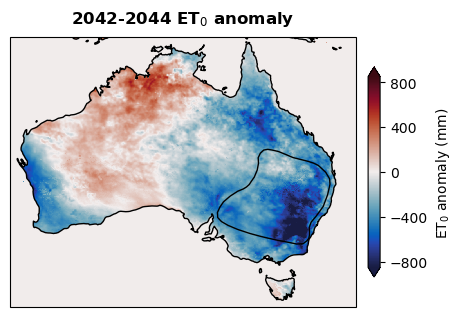

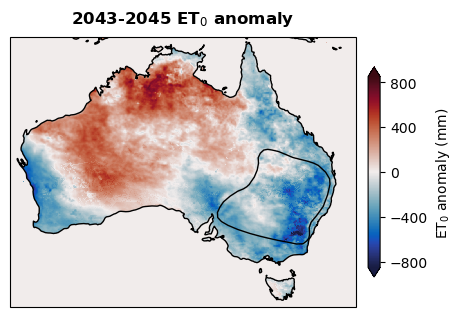

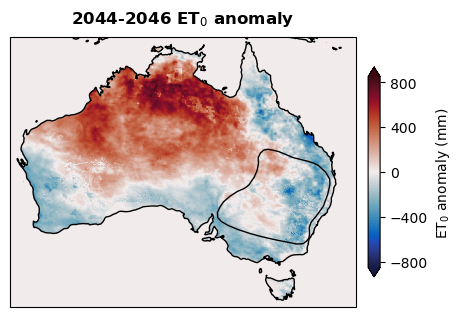

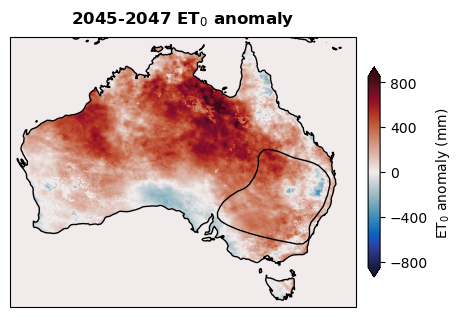

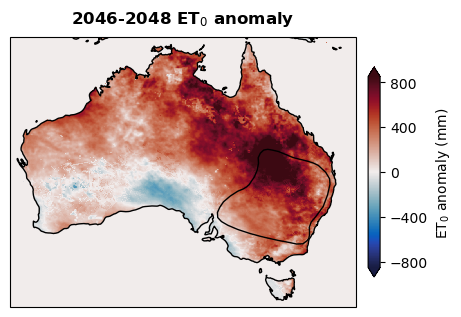

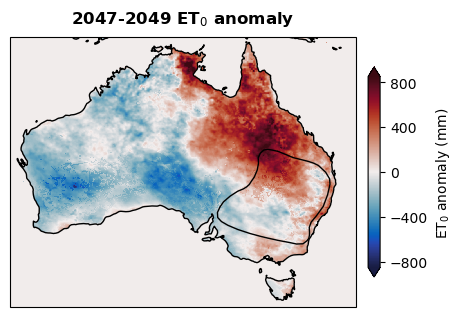

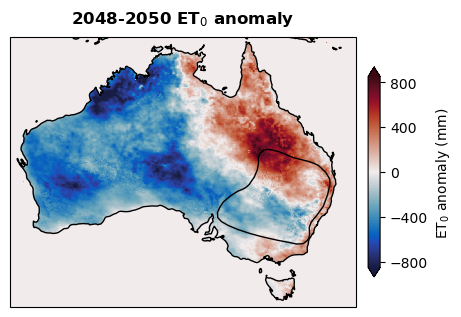

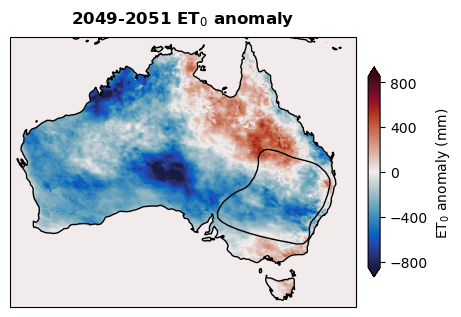

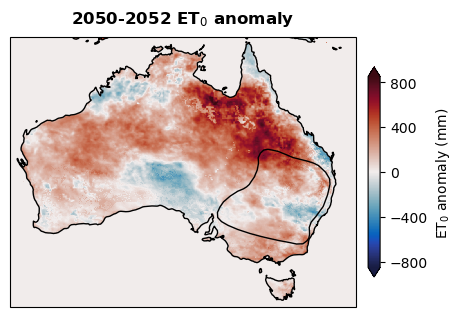

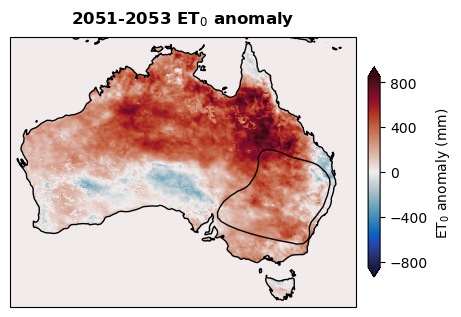

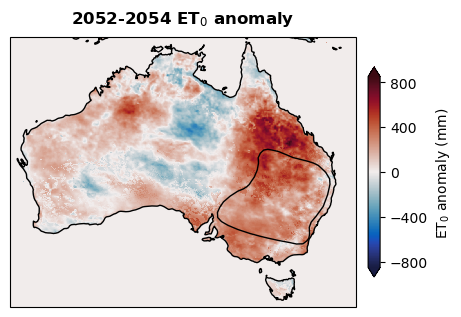

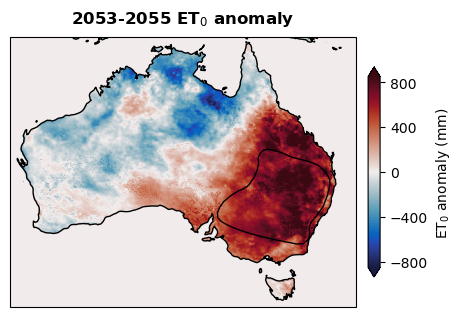

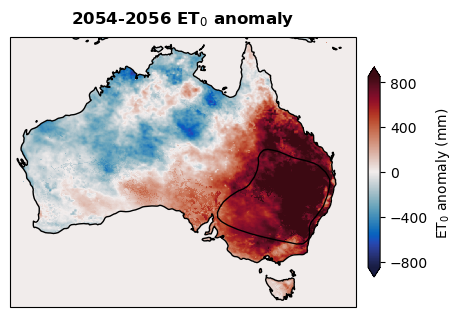

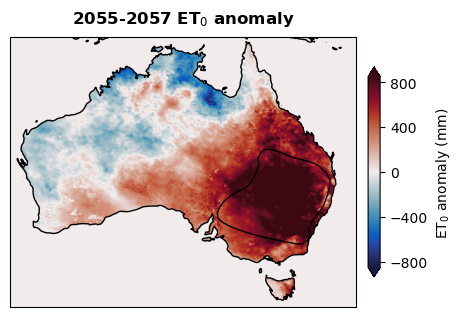

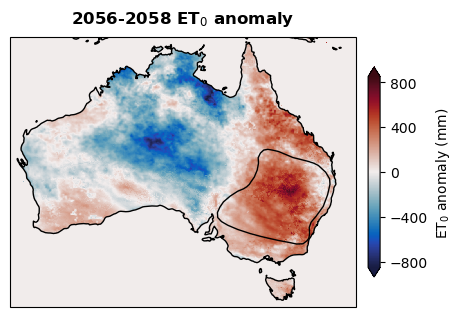

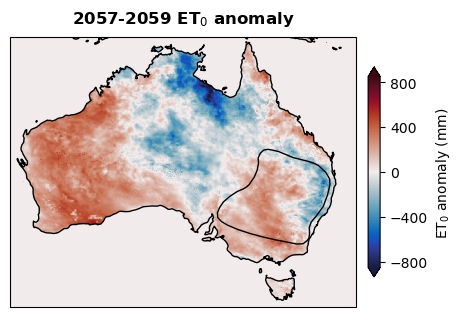

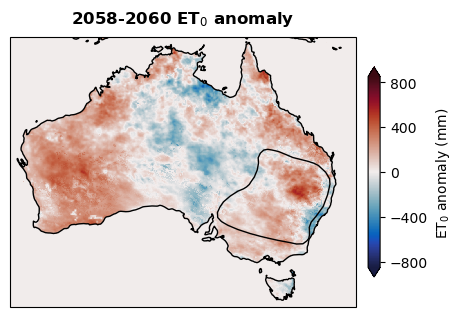

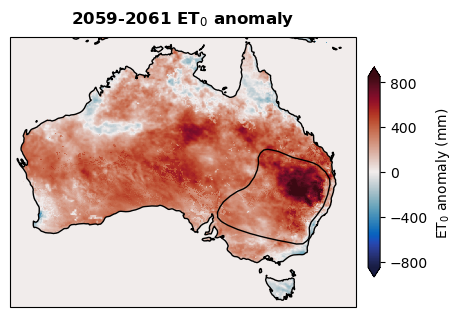

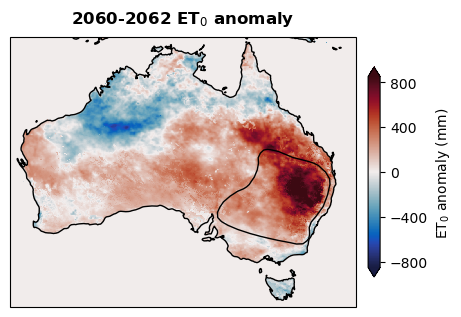

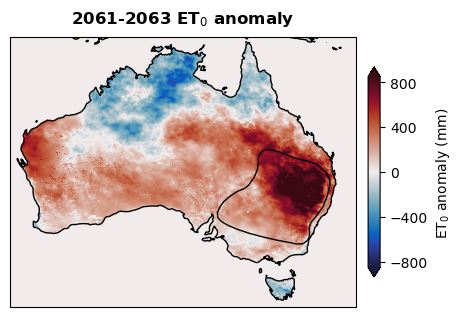

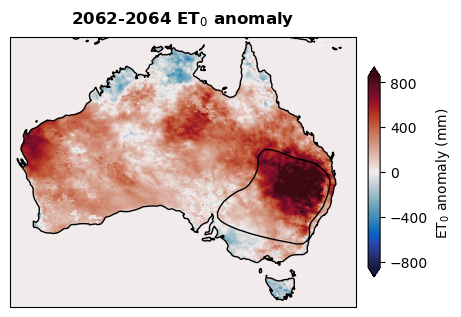

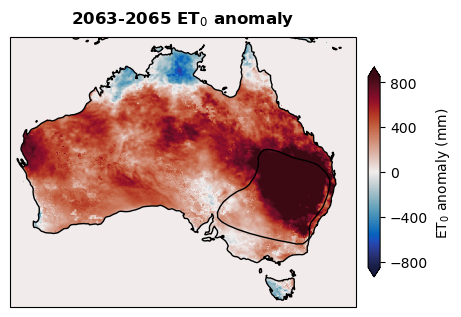

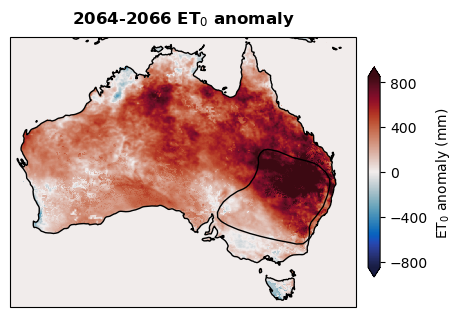

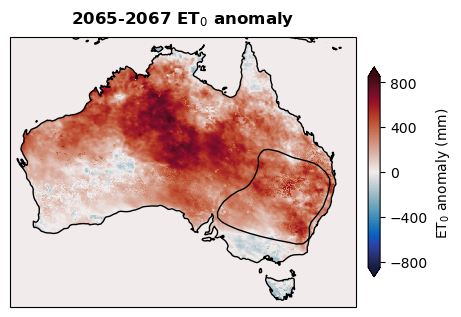

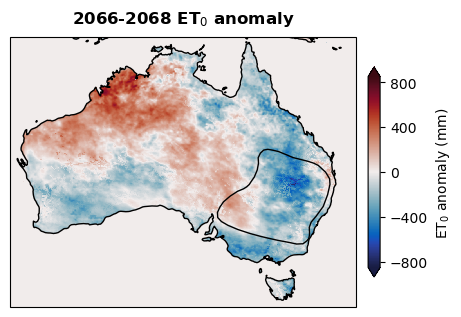

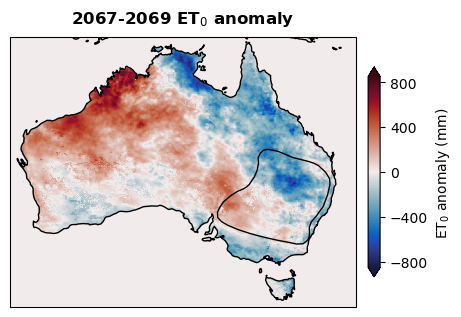

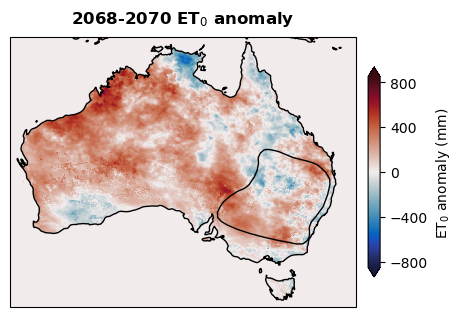

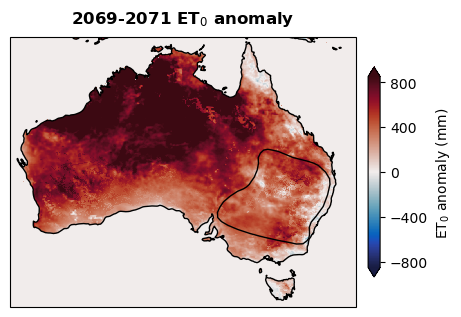

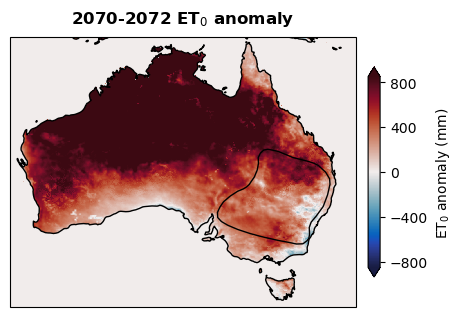

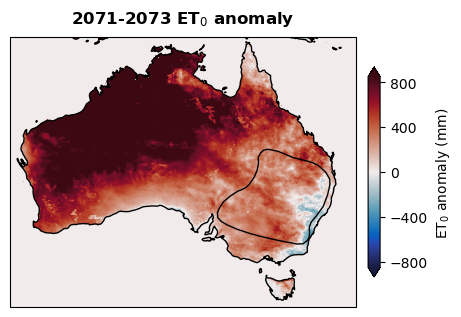

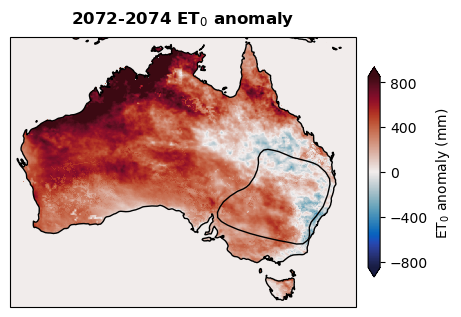

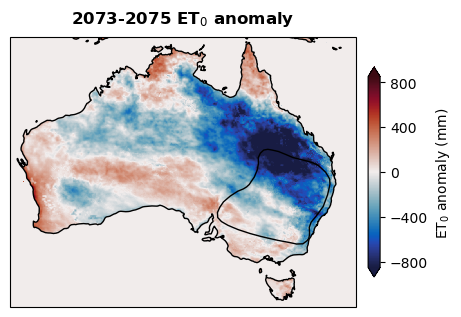

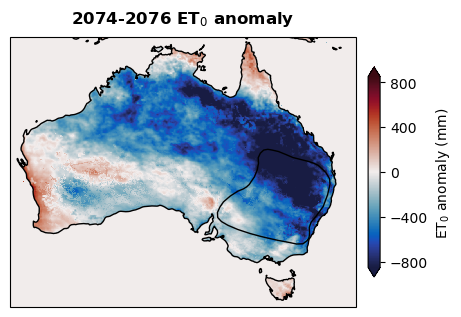

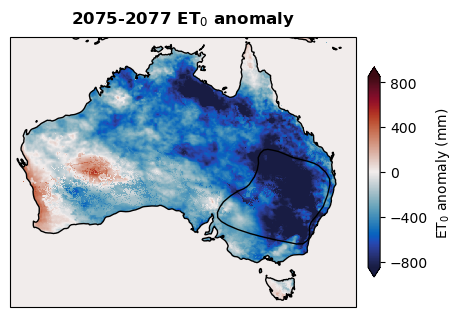

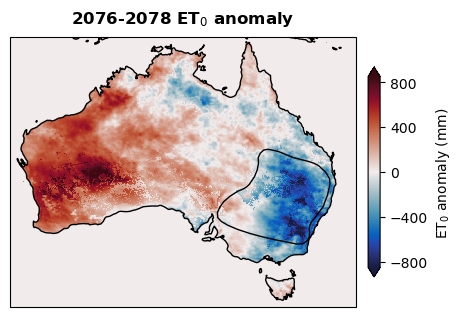

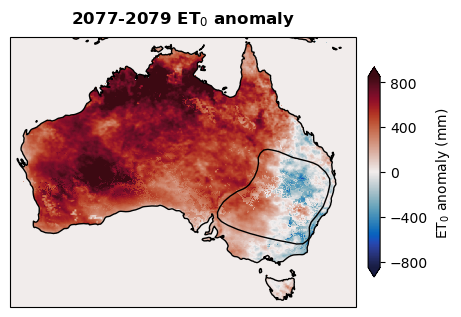

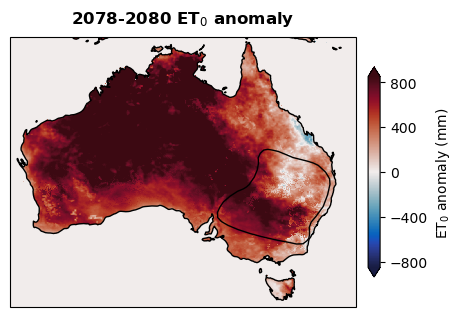

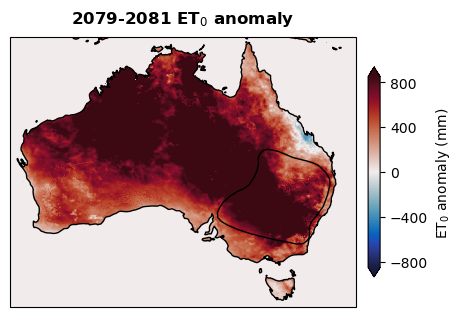

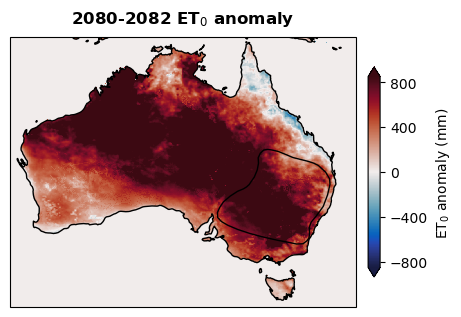

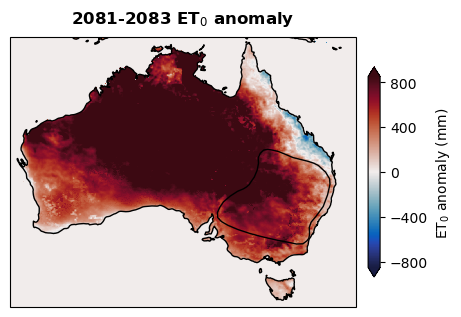

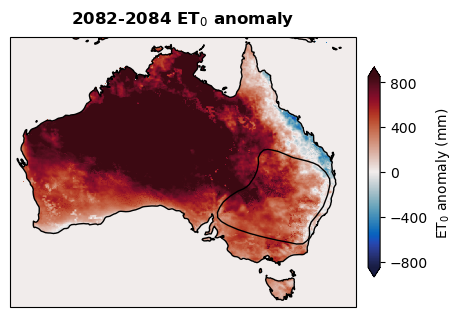

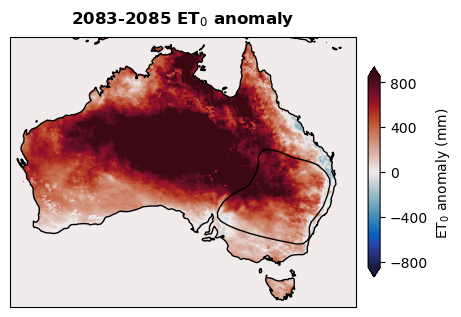

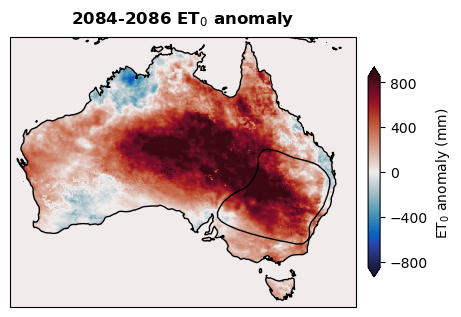

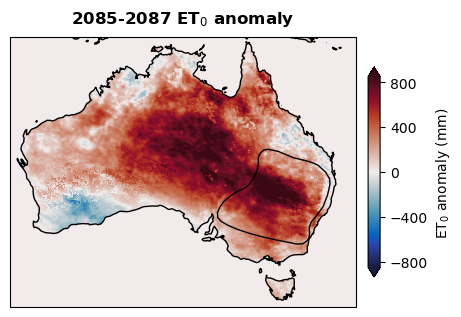

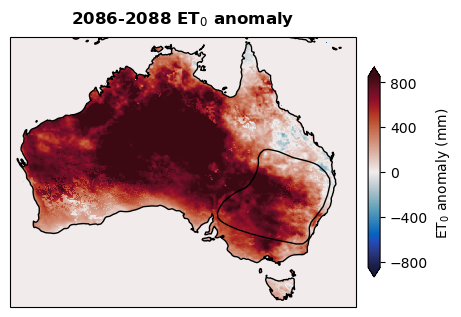

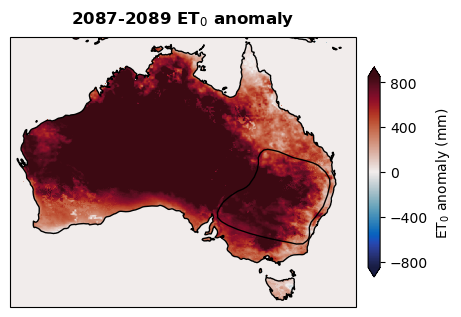

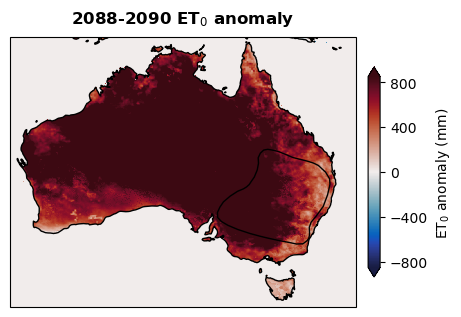

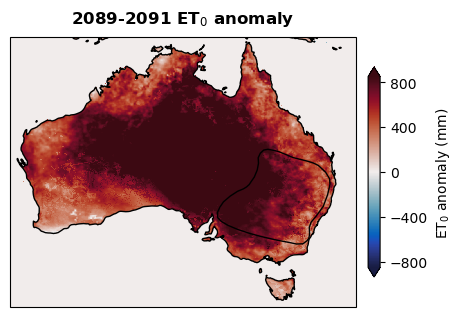

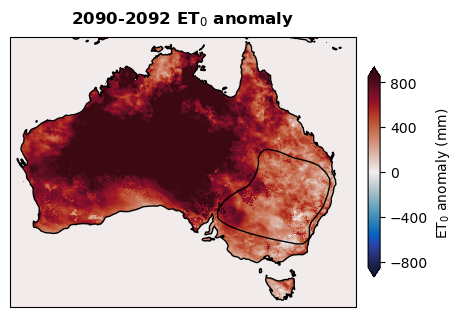

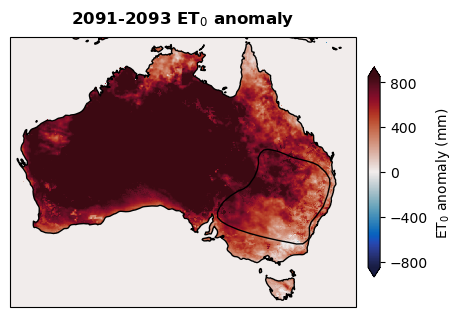

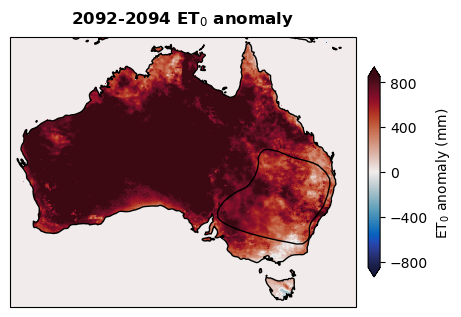

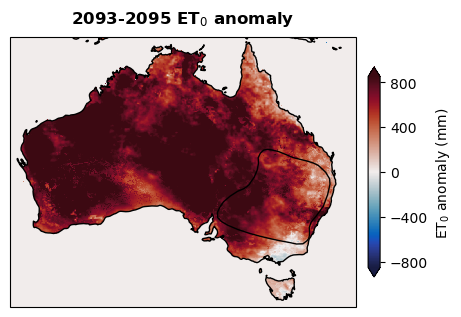

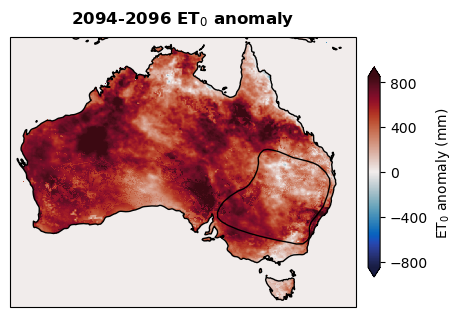

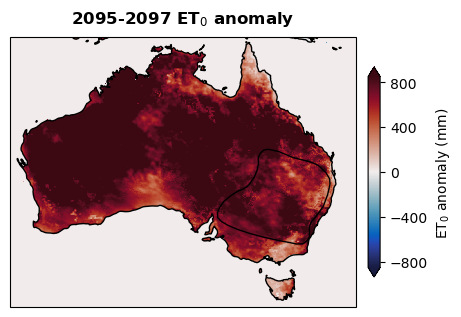

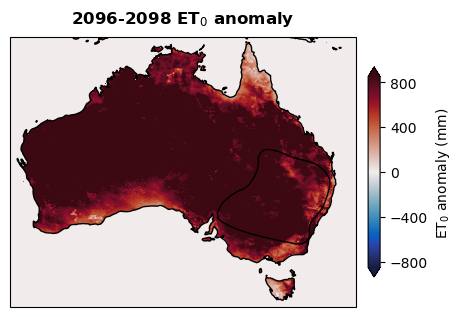

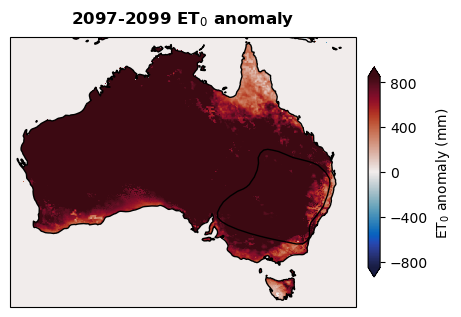

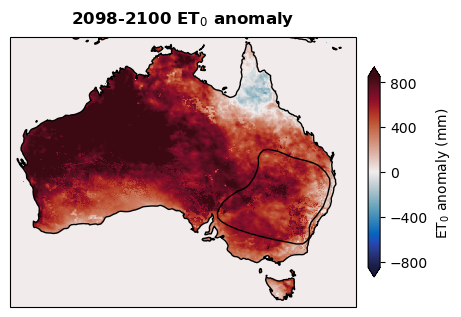

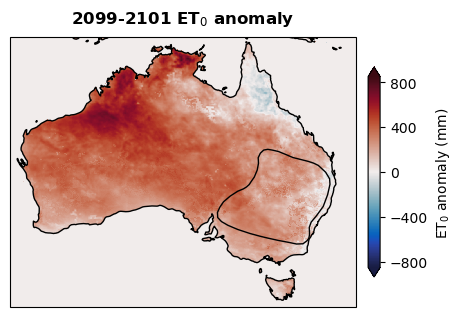

CPU times: user 7min 56s, sys: 58.7 s, total: 8min 54s
Wall time: 8min 38s


In [77]:
%%time
for year in range(2040,2100):
    create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=[112, 156.2, -42.3, -10],
        shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
        shapefile_linewidth = 1,
        plot_list=[[ET0_anom.sel(time=slice(str(year), str(year+2))).sum(dim='time')]],
        col_titles=[f'{str(year)}-{str(year+2)} ET$_0$ anomaly'],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.balance],
        cbar_labels=['ET$_0$ anomaly (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-850],
        cbar_maxs=[850])

In [8]:
ACS_downscaled_historical[8]

Key,Value
grid,AUST-05i
org,CSIRO
gcm,ACCESS-ESM1-5
scenario,historical
mdl_run,r6i1p1f1
rcm,CCAM-v2203-SN
ver,v1-r1
bc_org,NHP
bc,MRNBC
ref,BARRAR2


In [8]:
ens_idx = 8

In [9]:
sys.path.append('/g/data/mn51/users/jb6465/code/drought-github/submodules/gwls')
from gwl import *

In [10]:
import gc

In [ ]:
# input_dict = {}
# units_dict = {'R':'W/m2', 'T':'K', 'q':'kg/kg', 'U':'m/s', 'Patm':'Pa'}
# save_dir = '/g/data/mn51/users/jb6465/data/flash_drought/projections/ACCESS-ESM1-5_r6i1p1f1_CCAM-v2203-SN'


# input_dict['R'] = 86400 * xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='rsdsAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').rsdsAdjust.compute()
# input_dict['T'] = -273.15 + 0.5* (xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='tasmaxAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').tasmaxAdjust + xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='tasminAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').tasminAdjust).compute()
# input_dict['q'] = xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='hussAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').hussAdjust.compute()
# input_dict['U'] = xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='sfcWindAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').sfcWindAdjust.compute()
# input_dict['Patm'] = xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='psAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').psAdjust.compute()
# elev = xr.open_dataset(glob.glob(f'/g/data/ia39/australian-climate-service/release/CORDEX/output-CMIP6/DD/AUST-05i/CSIRO/ACCESS-ESM1-5/historical/r6i1p1f1/CCAM-v2203-SN/v1-r1/fx/orog/v20250311/*.nc')[0]).orog

for GWL in [1.5, 2.0, 3.0]:
    syear, eyear = get_GWL_syear_eyear('CMIP6','ACCESS-ESM1-5','r6i1p1f1','ssp370',GWL)
    for target_var in ['R', 'T', 'q', 'U', 'Patm']:
        start = time.time()
        target_var_gwl = input_dict[target_var].sel(time=input_dict[target_var]['time'].dt.year.isin(range(syear, eyear+1)))
        target_var_rolling = compute_rolling_xday(target_var_gwl, 7, centre_window=True)#.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).compute()
        driver_climo = compute_doy_climo(target_var_rolling)

        climo_key = 'climo_'+target_var
        units=units_dict[target_var]
        saver = xr.Dataset({f"{climo_key}": driver_climo.assign_attrs(long_name=f"{climo_key[-1]} driver climatology", units=str(units))}).reset_coords(drop=True).astype('float32').to_zarr(f"{save_dir}/GWL{GWL}_{climo_key}.zarr", mode="w", consolidated=True, encoding={f"{climo_key}": {"compressor": zarr.Blosc(cname='zstd', clevel=5, shuffle=1)}})
        end = time.time()
        print(f"~ GWL{GWL} {target_var} driver climo computed in {end - start:.2f} s")
        

~ GWL1.5 R driver climo computed in 298.08 s


In [1]:
# input_dict = {}
# input_dict['R'] = 86400 * xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='rsdsAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').rsdsAdjust.compute()
# input_dict['T'] = -273.15 + 0.5* (xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='tasmaxAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').tasmaxAdjust + xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='tasminAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').tasminAdjust).compute()
# input_dict['q'] = xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='hussAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').hussAdjust.compute()
# input_dict['U'] = xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='sfcWindAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').sfcWindAdjust.compute()
# input_dict['Patm'] = xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='psAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').psAdjust.compute()
# elev = xr.open_dataset(glob.glob(f'/g/data/ia39/australian-climate-service/release/CORDEX/output-CMIP6/DD/AUST-05i/CSIRO/ACCESS-ESM1-5/historical/r6i1p1f1/CCAM-v2203-SN/v1-r1/fx/orog/v20250311/*.nc')[0]).orog

# for GWL in [1.5, 2.0, 3.0]: #[1.2, 1.5, 2.0, 3.0]
#     syear, eyear = get_GWL_syear_eyear('CMIP6','ACCESS-ESM1-5','r6i1p1f1','ssp370',GWL)
#     R_gwl = input_dict['R'].sel(time=input_dict['R']['time'].dt.year.isin(range(syear, eyear+1)))
#     T_gwl = input_dict['T'].sel(time=input_dict['T']['time'].dt.year.isin(range(syear, eyear+1)))
#     q_gwl = input_dict['q'].sel(time=input_dict['q']['time'].dt.year.isin(range(syear, eyear+1)))
#     U_gwl = input_dict['U'].sel(time=input_dict['U']['time'].dt.year.isin(range(syear, eyear+1)))
#     Patm_gwl = input_dict['Patm'].sel(time=input_dict['Patm']['time'].dt.year.isin(range(syear, eyear+1)))

    
#     R_climo = compute_doy_climo(compute_rolling_xday(R_gwl, 7, centre_window=True))
#     T_climo = compute_doy_climo(compute_rolling_xday(T_gwl, 7, centre_window=True))
#     q_climo = compute_doy_climo(compute_rolling_xday(q_gwl, 7, centre_window=True))
#     U_climo = compute_doy_climo(compute_rolling_xday(U_gwl, 7, centre_window=True))
#     Patm_climo = compute_doy_climo(compute_rolling_xday(Patm_gwl, 7, centre_window=True))
    
#     sens_T, sens_R, sens_q, sens_U = compute_driver_sensivities(R_climo,T_climo,U_climo,q_climo,Patm_climo,elev,
#                                                                 short_tall_crop_switch = 'tall')
    
#     save_dir = '/g/data/mn51/users/jb6465/data/flash_drought/projections/ACCESS-ESM1-5_r6i1p1f1_CCAM-v2203-SN/driver_sensitivities/new'
#     sensitivity_key = ['sens_T', 'sens_R', 'sens_q', 'sens_U']
#     units = ['(mm/day)/(K)', '(mm/day)/(W/m2)', '(mm/day)/(kg/kg)', '(mm/day)/(m/s)']
    
#     for i, driver_sensitivity in enumerate([sens_T, sens_R, sens_q, sens_U]):
#         start = time.time()
#         saver = xr.Dataset({f"{sensitivity_key[i]}": driver_sensitivity.assign_attrs(long_name=f"{sensitivity_key[i][-1]} driver sensitvity", units=str(units[i]))}).reset_coords(drop=True).astype('float32').to_zarr(f"{save_dir}/GWL{GWL}_{sensitivity_key[i]}.zarr", mode="w", consolidated=True, encoding={f"{sensitivity_key[i]}": {"compressor": zarr.Blosc(cname='zstd', clevel=5, shuffle=1)}})
#         end = time.time()
#         print(f"~ GWL{GWL} {sensitivity_key[i][-1]} driver sensitivity computed in {end - start:.2f} s")

In [17]:
%%time
for GWL in [2.0, 3.0]:
    R_climo = xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/projections/ACCESS-ESM1-5_r6i1p1f1_CCAM-v2203-SN/climo/GWL{GWL}_climo_R.zarr').climo_R
    T_climo = xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/projections/ACCESS-ESM1-5_r6i1p1f1_CCAM-v2203-SN/climo/GWL{GWL}_climo_T.zarr').climo_T
    U_climo = xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/projections/ACCESS-ESM1-5_r6i1p1f1_CCAM-v2203-SN/climo/GWL{GWL}_climo_U.zarr').climo_U
    q_climo = xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/projections/ACCESS-ESM1-5_r6i1p1f1_CCAM-v2203-SN/climo/GWL{GWL}_climo_q.zarr').climo_q
    Patm_climo = xr.open_dataset(f'/g/data/mn51/users/jb6465/data/flash_drought/projections/ACCESS-ESM1-5_r6i1p1f1_CCAM-v2203-SN/climo/GWL{GWL}_climo_Patm.zarr')
    elev = xr.open_dataset(glob.glob(f'/g/data/ia39/australian-climate-service/release/CORDEX/output-CMIP6/DD/AUST-05i/CSIRO/ACCESS-ESM1-5/historical/r6i1p1f1/CCAM-v2203-SN/v1-r1/fx/orog/v20250311/*.nc')[0]).orog
    # sens_T, sens_R, sens_q, sens_U = compute_driver_sensivities(R_climo,T_climo,U_climo,q_climo,Patm_climo,elev,
    #                                                         short_tall_crop_switch = 'tall')
    break

CPU times: user 46.1 ms, sys: 22 ms, total: 68.1 ms
Wall time: 71.6 ms


In [1]:
# %%time
# sens_T, sens_R, sens_q, sens_U = compute_driver_sensivities(R_climo,T_climo,U_climo,q_climo,Patm_climo,elev,
#                                                             short_tall_crop_switch = 'tall')

In [2]:
# %%time
# input_dict['R'] = 86400 * xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='rsdsAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').rsdsAdjust
# input_dict['T'] = -273.15 + 0.5* (xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='tasmaxAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').tasmaxAdjust + xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='tasminAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').tasminAdjust)
# input_dict['q'] = xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='hussAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').hussAdjust
# input_dict['U'] = xr.open_mfdataset(ACS_downscaled_ssp370[0].select(var='sfcWindAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4').sfcWindAdjust
# elev = xr.open_dataset(glob.glob(f'/g/data/ia39/australian-climate-service/release/CORDEX/output-CMIP6/DD/AUST-05i/CSIRO/ACCESS-ESM1-5/historical/r6i1p1f1/CCAM-v2203-SN/v1-r1/fx/orog/v20250311/*.nc')[0]).orog

# for GWL in [2.0, 3.0]: #[1.2, 1.5, 2.0, 3.0]
#     syear, eyear = get_GWL_syear_eyear('CMIP6','ACCESS-ESM1-5','r6i1p1f1','ssp370',GWL)
#     R_gwl = input_dict['R'].sel(time=input_dict['R']['time'].dt.year.isin(range(syear, eyear+1))).compute()
#     T_gwl = input_dict['T'].sel(time=input_dict['T']['time'].dt.year.isin(range(syear, eyear+1))).compute()
#     q_gwl = input_dict['q'].sel(time=input_dict['q']['time'].dt.year.isin(range(syear, eyear+1))).compute()
#     U_gwl = input_dict['U'].sel(time=input_dict['U']['time'].dt.year.isin(range(syear, eyear+1))).compute()

#     T_anom = compute_daily_anom(compute_rolling_xday(T_gwl, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
#     R_anom = compute_daily_anom(compute_rolling_xday(R_gwl, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
#     q_anom = compute_daily_anom(compute_rolling_xday(q_gwl, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})
#     U_anom = compute_daily_anom(compute_rolling_xday(U_gwl, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'})

In [3]:
# %%time
# T_anom = compute_daily_anom(compute_rolling_xday(T, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).compute()
# R_anom = compute_daily_anom(compute_rolling_xday(R, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).compute()
# q_anom = compute_daily_anom(compute_rolling_xday(q, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).compute()
# U_anom = compute_daily_anom(compute_rolling_xday(U, 7, True)).chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).compute()

In [4]:
# for year in [2046, 2055, 2063, 2070, 2091, 2095]:
#     T_cont = mask_ocean((T_anom*sens_T.sel(doy=T_anom['time'].dt.dayofyear)).sel(time=slice(str(year), str(year+2))).sum(dim='time'))
#     R_cont = mask_ocean((R_anom*sens_R.sel(doy=R_anom['time'].dt.dayofyear)).sel(time=slice(str(year), str(year+2))).sum(dim='time'))
#     q_cont = mask_ocean((q_anom*sens_q.sel(doy=q_anom['time'].dt.dayofyear)).sel(time=slice(str(year), str(year+2))).sum(dim='time'))
#     U_cont = mask_ocean((U_anom*sens_U.sel(doy=U_anom['time'].dt.dayofyear)).sel(time=slice(str(year), str(year+2))).sum(dim='time'))
 
#     drivers = [T_cont, R_cont, q_cont, U_cont]
#     names = ['T', 'R', 'q', 'U']
#     stacked = xr.concat(drivers, dim='driver', coords='minimal', compat='override').assign_coords(driver=names)
#     ranked = xr.DataArray(rankdata(-stacked, axis=0), dims=stacked.dims, coords=stacked.coords)
#     ranked_drivers = {n: ranked.sel(driver=n) for n in names}
 
#     dominant_driver = ranked.idxmin(dim='driver')
#     driver_map = {'T': 1, 'R': 2, 'q': 3, 'U': 4}
#     dominant_driver_num = xr.DataArray(np.vectorize(driver_map.get)(dominant_driver.values), dims=dominant_driver.dims, coords=dominant_driver.coords)
 
#     create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=[90, 180, -40, 9],
#         shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
#         shapefile_linewidth = 1,
#         plot_list=[[dominant_driver_num.astype('float')]],
#         col_titles=[f'Dominant driver for {str(year)} - {str(year+2)}'],
#         col_titles_all_rows_switch=False,
#         cmap_list=[colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7'])],
#         cbar_labels=['Dominant driver'],
#         cbar_extensions=['both'],
#         cbar_width = 0.03,
#         cbar_height = 0.35,
#         cbar_nticks = [4],
#         cbar_tick_labels = ['-', 'T','R','q','U',],
#         cbar_x_y_loc = (0.93, 0.65/2),
#         cbar_mins=[0.5],
#         cbar_maxs=[4.5])

## $ET_0$ driver sensitivities

In [21]:
sys.path.append('/g/data/mn51/users/jb6465/code/drought-github/submodules/gwls')
from gwl import *

In [73]:
def fix_cftime(ds):
    return ds.assign_coords(time=pd.to_datetime(ds.time.values.astype(str)))

for ens_idx in range(1,14):
    #get info for save string
    GCM = str(ACS_downscaled_historical[ens_idx]).split('\n')[3].split()[-1]
    variant = str(ACS_downscaled_historical[ens_idx]).split('\n')[5].split()[-1]
    RCM = str(ACS_downscaled_historical[ens_idx]).split('\n')[6].split()[-1]
    BC = str(ACS_downscaled_historical[ens_idx]).split('\n')[8].split()[-1]+'_'+str(ACS_downscaled_historical[ens_idx]).split('\n')[9].split()[-1]+'_'+str(ACS_downscaled_historical[ens_idx]).split('\n')[10].split()[-1]
            
    #ingest inputs 
    Rs = xr.open_mfdataset(ACS_downscaled_historical[ens_idx].select(var='rsdsAdjust').get_files()+ACS_downscaled_ssp370[0].select(var='rsdsAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4', preprocess=fix_cftime).rsdsAdjust
    T = 0.5* (xr.open_mfdataset(ACS_downscaled_historical[ens_idx].select(var='tasmaxAdjust').get_files()+ACS_downscaled_ssp370[0].select(var='tasmaxAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4', preprocess=fix_cftime).tasmaxAdjust + xr.open_mfdataset(ACS_downscaled_historical[ens_idx].select(var='tasminAdjust').get_files()+ACS_downscaled_ssp370[0].select(var='tasminAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4', preprocess=fix_cftime).tasminAdjust)
    q = xr.open_mfdataset(ACS_downscaled_historical[ens_idx].select(var='hussAdjust').get_files()+ACS_downscaled_ssp370[0].select(var='hussAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4', preprocess=fix_cftime).hussAdjust
    U = xr.open_mfdataset(ACS_downscaled_historical[ens_idx].select(var='sfcWindAdjust').get_files()+ACS_downscaled_ssp370[0].select(var='sfcWindAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4', preprocess=fix_cftime).sfcWindAdjust 
    Patm = xr.open_mfdataset(ACS_downscaled_historical[ens_idx].select(var='psAdjust').get_files()+ACS_downscaled_ssp370[0].select(var='psAdjust').get_files(), combine='nested', concat_dim='time', parallel = True, engine='netcdf4', preprocess=fix_cftime).psAdjust    
    elev = xr.open_dataset(glob.glob(f'/g/data/ia39/australian-climate-service/release/CORDEX/output-CMIP6/DD/AUST-05i/BOM/{GCM}/historical/{variant}/{RCM}/v1-r1/fx/orog/v20250311/*.nc')[0] if RCM == 'BARPA-R' else glob.glob(f'/g/data/ia39/australian-climate-service/release/CORDEX/output-CMIP6/DD/AUST-05i/CSIRO/{GCM}/historical/{variant}/{RCM}/v1-r1/fx/orog/v20250311/*.nc')[0]).orog

In [1]:
# %%time
# for gwl in [1.2, 1.5, 2.0, 3.0]:
#     R_climo = compute_doy_climo(compute_rolling_xday((Rs*86400).sel(time=Rs.time.dt.year.isin(range(syear, eyear+1))), 7, centre_window=True)).compute()
#     T_climo = compute_doy_climo(compute_rolling_xday((T-273.15).sel(time=T.time.dt.year.isin(range(syear, eyear+1))), 7, centre_window=True)).compute()
#     q_climo = compute_doy_climo(compute_rolling_xday(q.sel(time=q.time.dt.year.isin(range(syear, eyear+1))), 7, centre_window=True)).compute()
#     U_climo = compute_doy_climo(compute_rolling_xday(U.sel(time=U.time.dt.year.isin(range(syear, eyear+1))), 7, centre_window=True)).compute()
#     Patm_climo = compute_doy_climo(compute_rolling_xday(Patm.sel(time=Patm.time.dt.year.isin(range(syear, eyear+1))), 7, centre_window=True)).compute()
#     break

In [2]:
# %%time
# sens_T, sens_R, sens_q, sens_U = compute_driver_sensivities(R_climo,T_climo,U_climo,q_climo,Patm_climo,elev,
#                                                             short_tall_crop_switch = 'tall')